In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix , ConfusionMatrixDisplay,classification_report

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam

tf.random.set_seed(42)
np.random.seed(42)

In [11]:
train_ds=pd.read_csv(r"D:\dl-workspace\notebooks\datasets\Fashion MNIST\fashion-mnist_train.csv\fashion-mnist_train.csv")
test_ds=pd.read_csv(r"D:\dl-workspace\notebooks\datasets\Fashion MNIST\fashion-mnist_test.csv\fashion-mnist_test.csv")

In [8]:
train_ds.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [10]:
y_train=train_ds.iloc[:,0].values.astype("int64")
x_train=train_ds.iloc[:,1:].values.astype("float32").reshape(-1,28,28)

print(x_train.shape)
print(y_train.shape)

(60000, 28, 28)
(60000,)


In [13]:
test_ds.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,9,8,...,103,87,56,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,34,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,14,53,99,...,0,0,0,0,63,53,31,0,0,0
3,2,0,0,0,0,0,0,0,0,0,...,137,126,140,0,133,224,222,56,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [14]:
y_test=test_ds.iloc[:,0].values.astype("int64")
x_test=test_ds.iloc[:,1:].values.astype("float32").reshape(-1,28,28)

print(x_test.shape)
print(y_test.shape)

(10000, 28, 28)
(10000,)


In [15]:
print(np.unique(y_train))

[0 1 2 3 4 5 6 7 8 9]


In [16]:
x_train=x_train/255.0
x_test=x_test/255.0

x_train=x_train.reshape(-1,28,28,1)
x_test=x_test.reshape(-1,28,28,1)

y_train_sc=to_categorical(y_train,10)
y_test_sc=to_categorical(y_test,10)

print(x_train.min())
print(x_train.max())

0.0
1.0


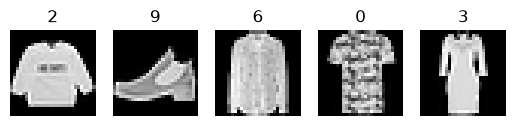

In [17]:
for i in range(5):
    plt.subplot(1,5,i+1)
    plt.imshow(x_train[i].reshape(28,28),cmap="gray")
    plt.title(y_train[i])
    plt.axis("off")
plt.show()

In [18]:
model=keras.Sequential([
    layers.Input(shape=(28,28,1)),
    layers.Conv2D(32,(3,3), activation="relu"),
    layers.MaxPooling2D((2,2,)),
    layers.Conv2D(64,(3,3),activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(128,activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10,activation="softmax")
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
model.compile(
    loss="categorical_crossentropy",
    optimizer=Adam(learning_rate=0.001),
    metrics=["accuracy"]
)
history=model.fit(
    x_train,
    y_train_sc,
    validation_split=0.1,
    epochs=20,
    batch_size=64,
    verbose=1
)

Epoch 1/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.7959 - loss: 0.5566 - val_accuracy: 0.8665 - val_loss: 0.3784
Epoch 2/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.8662 - loss: 0.3674 - val_accuracy: 0.8818 - val_loss: 0.3331
Epoch 3/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8835 - loss: 0.3197 - val_accuracy: 0.8937 - val_loss: 0.2998
Epoch 4/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8939 - loss: 0.2892 - val_accuracy: 0.8962 - val_loss: 0.2788
Epoch 5/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.9046 - loss: 0.2619 - val_accuracy: 0.9033 - val_loss: 0.2706
Epoch 6/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9107 - loss: 0.2426 - val_accuracy: 0.9073 - val_loss: 0.2551
Epoch 7/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.9180 - loss: 0.2248 - val_accuracy: 0.9078 - val_loss: 0.2486
Epoch 8/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.9221 - loss: 0.2073 - val_accu

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9180 - loss: 0.3034
0.3033500611782074
0.9179999828338623
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
              precision    recall  f1-score   support

           0       0.85      0.86      0.86      1000
           1       0.99      0.99      0.99      1000
           2       0.88      0.86      0.87      1000
           3       0.93      0.94      0.93      1000
           4       0.88      0.88      0.88      1000
           5       0.99      0.98      0.98      1000
           6       0.77      0.76      0.76      1000
           7       0.96      0.96      0.96      1000
           8       0.99      0.98      0.98      1000
           9       0.96      0.98      0.97      1000

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000



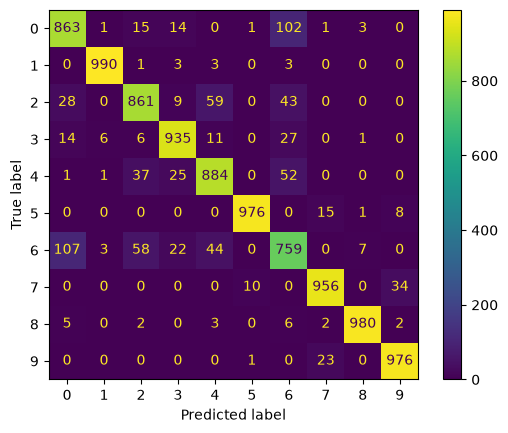

In [21]:
test_loss, test_acc=model.evaluate(x_test,y_test_sc)
print(test_loss)
print(test_acc)

y_pred=model.predict(x_test).argmax(axis=1)
print(classification_report(y_test,y_pred))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred)
plt.show()

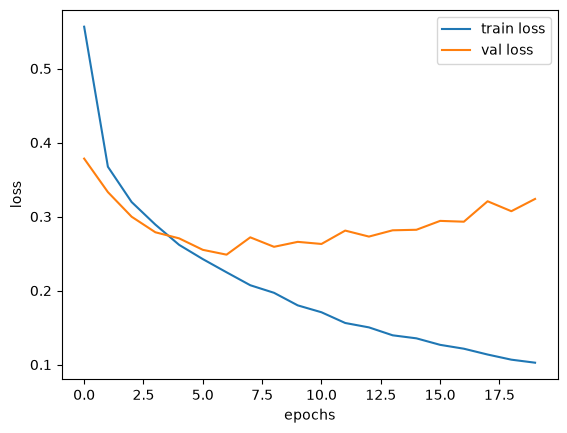

In [22]:
plt.plot(history.history["loss"],label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.legend()
plt.show()